# 06 · Can her NPK model work? An EC check on real farm data

Low-cost NPK probes (DFRobot SEN0605 / JXCT class) convert **one conductivity signal** into N, P and K at fixed ratios (Baldi et al. 2026, *Horticulturae*). So "forecast the NPK readings" = "forecast EC."

No public continuous NPK-probe dataset was available, so we use the **Cook Agronomy Farm** (WSU): 42 field sites, daily bulk EC, moisture and soil temp at 0.3 m (Decagon 5TE), 2011 to 2012.

In [1]:
# Setup: works locally (pip install -e . from the repo root) and on Google Colab
import sys, warnings
warnings.filterwarnings("ignore")
if "google.colab" in sys.modules:
    # Upload soilcast.zip to Google Drive (MyDrive) first
    from google.colab import drive
    drive.mount("/content/drive")
    !unzip -q -o /content/drive/MyDrive/soilcast.zip -d /content
    %cd /content/soilcast
    !pip install -q -e ".[gpu-trees]"
    sys.path.insert(0, "/content/soilcast/src")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from soilcast.config import PROCESSED, RAW, RESULTS
from soilcast.plotting import set_style, model_color, SERIES, MUTED
set_style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
RESULTS.mkdir(exist_ok=True)

In [2]:
from soilcast.cookfarm import daily_panel, EC_FEATURES
from soilcast.models import fit_predict_delta
from soilcast.evaluate import rmse
p = daily_panel(port=1)
x = p.dropna(subset=["ec_uScm", "vw", "st"])
print(len(x), "site-days with EC, moisture and temperature;", x.SOURCEID.nunique(), "sites")

22265 site-days with EC, moisture and temperature; 42 sites


## How much of EC is just moisture and temperature?

within-site R2 of EC ~ moisture + temperature: median 0.69, IQR [0.55, 0.78]


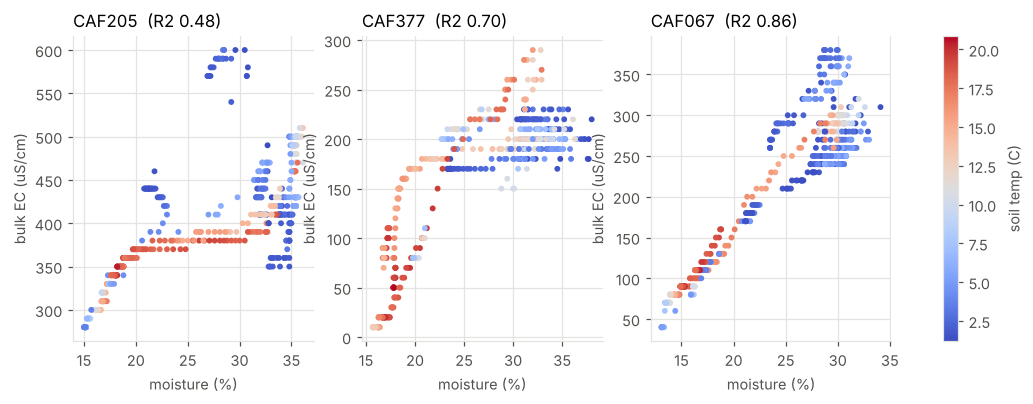

In [3]:
from sklearn.linear_model import LinearRegression
r2 = {}
for sid, g in x.groupby("SOURCEID"):
    if len(g) > 100:
        r2[sid] = LinearRegression().fit(g[["vw", "st"]], g.ec_uScm).score(g[["vw", "st"]], g.ec_uScm)
r2 = pd.Series(r2)
print(f"within-site R2 of EC ~ moisture + temperature: median {r2.median():.2f}, IQR [{r2.quantile(.25):.2f}, {r2.quantile(.75):.2f}]")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=False)
for ax, sid in zip(axes, r2.sort_values().index[[5, len(r2) // 2, -5]]):
    g = x[x.SOURCEID == sid]
    sc = ax.scatter(100 * g.vw, g.ec_uScm, c=g.st, s=8, cmap="coolwarm")
    ax.set(title=f"{sid}  (R2 {r2[sid]:.2f})", xlabel="moisture (%)", ylabel="bulk EC (uS/cm)")
plt.colorbar(sc, ax=axes, label="soil temp (C)");

Sensor resolution matters too: the 5TE reports EC in 0.01 dS/m steps (= 10 µS/cm), so small day-to-day changes are quantization.

## Forecasting EC 1, 2, 3 days ahead

In [4]:
rows = []
for hzn in (1, 2, 3):
    cols = EC_FEATURES + [f"fc_precip_{hzn}d", f"fc_tmax_{hzn}d"]
    q = p.dropna(subset=["ec_uScm", f"ec_t{hzn}"])
    tr, te = q[q.year == 2011], q[q.year == 2012]
    pr = {"persistence": te.ec_uScm.to_numpy()}
    for kind in ("linear", "gbm"):
        pr[kind], _ = fit_predict_delta(kind, tr[cols], tr.ec_uScm, tr[f"ec_t{hzn}"], te[cols], te.ec_uScm)
    base = rmse(te[f"ec_t{hzn}"], pr["persistence"])
    for k, yhat in pr.items():
        rows.append({"horizon_days": hzn, "model": k, "RMSE_uScm": rmse(te[f"ec_t{hzn}"], yhat),
                     "MAE_uScm": np.mean(np.abs(te[f"ec_t{hzn}"] - yhat)), "skill_vs_persistence": 1 - rmse(te[f"ec_t{hzn}"], yhat) / base})
ec = pd.DataFrame(rows); ec.to_csv(RESULTS / "06_ec_forecast.csv", index=False); ec.round(3)

,horizon_days,model,RMSE_uScm,MAE_uScm,skill_vs_persistence
0,1,persistence,16.268,4.203,0.000
1,1,linear,15.966,5.120,0.019
2,1,gbm,16.031,5.412,0.015
3,2,persistence,23.640,7.035,0.000
4,2,linear,23.144,8.187,0.021
5,2,gbm,23.497,8.894,0.006
6,3,persistence,26.600,9.157,0.000
7,3,linear,25.927,10.551,0.025
8,3,gbm,26.382,11.423,0.008


## Takeaways
- Within a site, moisture and temperature explain most of EC's day-to-day variation, so EC adds little independent nutrient information.
- EC forecasts barely beat persistence at any horizon. A model predicting the probe's N, P and K would inherit this, times three fixed ratios.
- **Recommendation:** replace the NPK forecast with the nitrate loss risk index (notebook 05), and use NPK/EC readings only as a "pull a soil test here" flag until lab samples exist to validate them.